# Lecture 22 — Figures from an Idea: building a schematic from scratch
### EES 3350/5350 · Python in Earth Science · Wednesday, October 28, 2026 

Every figure so far started with **data**: load a file, pick columns, plot. But a lot of the most useful figures in Earth science have **no data at all**. They're **schematics**: drawings of an idea, like "a hillslope fails when it gets wet" or "a flood grows as tributaries join."

You could draw a schematic in PowerPoint. Drawing it in Python means you can change one number and redraw it, keep its style consistent with your data figures, and know exactly what every curve means.

Today, we'll go from a **sketch on paper** to a finished figure, one array at a time.

**Learning objectives**
- sketch a figure on paper **before** writing code: what's on each axis, and what shape each curve takes
- translate shapes into pieces you can compute: a straight line, a step, a decay
- build a curve **one piece at a time**, plotting after each step
- style a figure as a schematic: no ticks, no box, labels that point to a feature

---
## Part 0 : get today's notebook

```
cd ~/course-materials
git pull
cp week10/22_schematic_figures.ipynb ~/LastName_EES3350/ees-3350-5350-week09-username/22_schematic_figures_LastName.ipynb
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Part 0.5 : some background

Before we draw floods, we need to know what a river does on an **ordinary** day.

**Discharge** is how much water flows past a spot each second, usually measured in cubic meters per second (m$^3$/s). Think of standing on a bridge and measuring the volume of water that passes under you every second.

As you walk **downstream**, the discharge almost always **grows**, because more and more land drains into the river:
- where a **tributary** (a branch of the river) joins, all water form its watershed arrives at once, so the discharge **jumps** right below the junction.

The land that drains into a river at any point is its **drainage area**. Drainage area grows downstream, so discharge does too. That's why the Cumberland River here in Nashville carries much more water than one of its small headwater creeks on the Cumberland Plateau.

Here's that idea as a schematic. There are no real distances or discharges: 0 is the headwaters, 1 is the mount, and the discharge numbers only show the **shape**.

![discharge of a river](../figures/ordinary_river.png)

There are four things to notice here:
- **The river gets less steep as the water grows.** The tan shape is the river's **longitudinal profile**: the elevation of the channel bed from headwaters to mouth. Most rivers have this **concave-up** shape, steep in the headwaters and gentle near the mouth. Small, steep headwater streams turn into big, gently sloping rivers downstream.
- **Discharge always goes up downstream**, gently between tributaries and in a jump at each one.
- **The jumps in discharge get bigger downstream.** Tributaries that join lower down drain bigger areas themselves, so they bring more water.
- **Discharge is small.** The y-axis runs to 1 on purpose: the floods we're about to draw are on the same scale, and an ordinary day barely gets off the floor.

### Question:
A flood is "more water than normal." Using this figure, predict: if heavy rain falls over the **whole** watershed, what would the curve look like? If instead a dam breaks **at the headwaters** while thee rest of the watershed stays dry, what would it look like?

---
## Part 1 : sketch first, code second

**Put your laptop screen down for this part.** You need a pen/pencil and paper.

Here's the idea we want to draw. Two very different kinds of flood can move down the same river:
- a **meteoric (rainfall induced) flood**. When it rains, rain falls over the whole watershed. As you go downstream, more and more of the watershed drains into the river, so the peak discharge grows downstream. Where a big **tributary** joins, the discharge jumps up
- an **outburst flood**. A natural (or manmade) dam fails and released impounded water all at once. The peak discharge occurs at the breach, where it's large, and then **shrinks** downstream as the flood wave spreads out.

![drainage basins](../figures/meteoric_vs_outburst_drainage_basins.png)


<div class="alert alert-info"> 

### Exercise 1 : Sketch it (5 minutes)

On paper, draw **two small graphs side by side, one for each kind of flood. For each:
1. What goes on the x-axis? What goes on the y-axis?
2. Does the curve go **up** or **down** as you go downstream? Is it **smooth**, or does it have jumps?
3. Where would you put labels to point out the important features?

Compare your sketch with your teammates'. Don't worry about numbers. There aren't any.

</div>

<details>
<summary style="color:green;"><strong>What a sketch might look like.</strong></summary>

Both graphs: **distance downstream** on x, **peak discharge** on y. No numbers on either axis: this is about the **shape**.

- **Meteoric:** starts low at the headwaters and climbs gently to the right, with a sudden step up at each tributary. Labels: "headwaters," "tributary" at each step.
- **Outburst:** starts very high at the left edge (the breach), then curves down quickly at first and more slowly later, leveling off toward the normal flow in the river. Labels: "dam breach," and something about why it shrinks.
</details>

Notice what you just did: you decided **what the figure should show** before deciding **how** to code it. That's the most important step, and it's the one people skip.

---
## Part 2 : shapes become pieces

Every curve in your sketch is built from a few simple shapes, and each shape is something you already know how to compute:

|**what you drew**|**what it means**|**question to answer**|**what you type**|**from**|
|:--|:--|:--|:--|:--|
|the x-axis, smooth run of points| "distance downstream", no units| what creates a linear space smoothly? |________________ | Lecture 14 |
|a line that climbes steadily| a **start** value plus a **slope** times x | what does this equation look like (how do we plot a line)? |________________ | Lecture 14 |
|a sudden jump at one place| **add** an amount to every point past that place| remember `+=`? How could we add a value at every point PAST a certain place downstream? |________________ | Lecture 15 |
|a curve that drops fast, then slower| **some equation tbd**| what's the math for to recreate this curve (remember numpy functions)?| ________________ | Lab 06 |
|one shape riding on top of another| add the two arrays together| how do we add two arrays together? | ________________ | Lecture 14 (array math)|

Let's decide to use x from **0 to 1** on purpose. A schematic has no real distances, so 0 means "the top of the river" and 1 means "the bottom", and every position is a fraction of the way down. That makes the numbers easy to think about: a tributary at `0.25` is a quarter of the way down.

---
## Part 3 : figure our your functions

First, we need to figure out what functions we will need to plot based on what we drew. Do the following exercise with your team.
![drainage basins](../figures/function_plots.png)


<div class="alert alert-info">

### Exercise 1
Look back at the sketches you drew in Part 1. For each of the following curves you drew, which panel (or panels) does it look like in the figure above? Write the simplied function in python form near each line you believe it represents on your figure.

</div>




## Part 4 : build it one piece at at ime.


### The meteoric flood

#### **Piece 1: the x-axis**. 
Let's make 500 points from the top of the river to the bottom, so:

In [21]:
x = np.linspace(0, 1, 500)
print(x[:3], x[-3:], x.shape)

[0.         0.00200401 0.00400802] [0.99599198 0.99799599 1.        ] (500,)


<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
x = np.linspace(0, 1, 500)
print(x[:3], x[-3:], x.shape)
```
---
```
[0.         0.00200401 0.00400802] [0.99599198 0.99799599 1.        ] (500,)
```

#### **Piece 2: a gentle climb** 
The peak discharge starts low at the headwaters and grows a little more as hillslopes drain into the river. 

> **What's a good, equation for a low slope line in this space?**

Let's plot an option to check that it looks like the sketch.

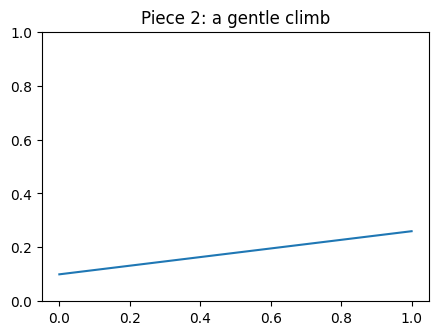

In [3]:
# first attempt at an equation
q_meteoric = 0.1 + 0.16*x

# now plot
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric)
ax.set_ylim(0, 1)
ax.set_title("Piece 2: a gentle climb");

<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
x = np.linspace(0, 1, 500)

# first attempt at an equation
q_meteoric = 0.08 + 0.18 * x 

# now plot
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric)
ax.set_ylim(0, 1)
ax.set_title("Piece 2: a gentle climb");
```
---
![piece 2](../figures/piece2.png)


##### Do you think that's low enough slope? 
Compare to the figure at the top of the lecture notebook. If you don't think it's low enough, what do we change to make it lower slope?

#### **Piece 3: the tributaries**. 
Three tributaries join, at 35%, 53%, and 78% of the way down. Each one adds discharge to **every point downstream of it**. 

> "Every point downstream of 0.25"...what does that remind you of?
<details>
<summary style="color:green;"><strong>answer.</strong></summary>
A mask! You could also think of it as at every distance greater than 0.25, do something. Which is the logic we use for masks. We can then "add to thoise points" as our mask assignment move from Lecture 15.

</details>

> What amount should we add at each tributary?
<details>
<summary style="color:green;"><strong>answer.</strong></summary>
up to you! but it should roughly scale to drainage area of those tributaries.
</details>

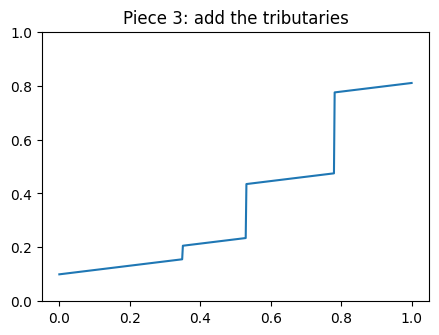

In [22]:
q_meteoric = 0.1 + 0.16*x

q_meteoric[x >= 0.35] += 0.05   # first tributary
q_meteoric[x >= 0.53] += 0.2   # second tributary
q_meteoric[x >= 0.78] += 0.3   # third tributary

# and plot
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric)
ax.set_ylim(0, 1)
ax.set_title("Piece 3: add the tributaries");

<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
q_meteoric[x >= 0.25] += 0.12   # first tributary
q_meteoric[x >= 0.52] += 0.12   # second tributary
q_meteoric[x >= 0.78] += 0.12   # third tributary

# and plot
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric)
ax.set_ylim(0, 1)
ax.set_title("Piece 3: add the tributaries")
```
---
![piece 3](../figures/piece3.png)

##### That's the sketch! 

The whole point of this is thinking through a problem. What if we wanted to add tributaries or easily change the amount each tributary added? Instead of individually writing each step change at a tributary junction, we can make parallel lists and then write a loop that uses `zip()` to pair them up (Lecture 10):

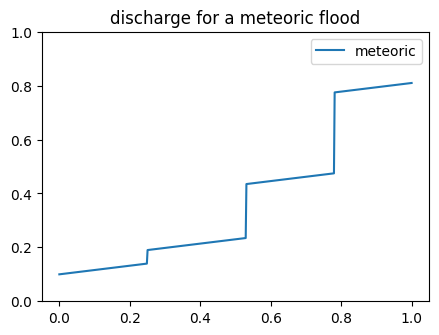

In [5]:
x = np.linspace(0, 1, 500)
trib_locations = [0.25, 0.53, 0.78]   # where each tributary joins (fraction of the way down)
trib_steps = [0.05, 0.2, 0.3]       # how much discharge each one adds

q_meteoric = 0.1 + 0.16*x

for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric, label="meteoric")
ax.set_ylim(0, 1)
ax.set_title("discharge for a meteoric flood");
ax.legend();

Now we only have to edit the two lists to change the figure.

<div class="alert alert-danger">

### Common mistake: building on top of an old version

`+=` changes `q_meteoric` **in place**. If you run the loop cell twice without re-running the generation of your original function (`q_meteoric = 0.18*x +0.08`), every tributary gets added **twice**. That's why the startin line is in the same cell as the loop: every time you run the cell, it starts over from scratch.
    
</div>

### The outburst flood

#### **Piece 1: the river's normal flow.**

Even without the outburst, there's some water in the river, and it grows a little downstream. Call it the **background** flow. Write an equation that intersects the y-axis at 0.05 and has a slope of 0.10.

In [6]:
q_background = 0.05 + 0.10*x        # from 0.05 at the top to 0.15 at the bottom

<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
q_background = 0.10*x + 0.05        # from 0.05 at the top to 0.15 at the bottom

#### **Piece 2: the outburst on top.**

At the breach (x = 0), the outburst adds a lot of water: enough to bring the total to 0.85. Downstream it decays. 
> What function did you decide represents this behavior?

<details>
<summary style="color:green;"><strong>answer.</strong></summary>

Exponential decay! or
```python
np.exp(=-x / 0.2)
```
</details>

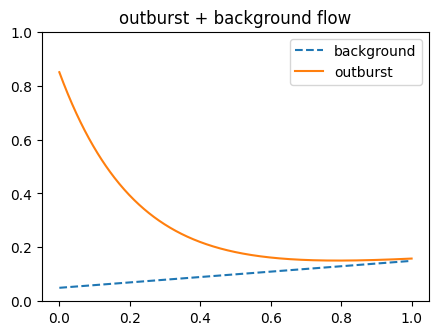

In [7]:
q_background = 0.10*x + 0.05
q_outburst = q_background + 0.8 * np.exp(-x / 0.22) # write your equation to represent this decay, adding your q_background to it first

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_background, linestyle="--", label="background")
ax.plot(x, q_outburst, label="outburst")
ax.set_ylim(0, 1)
ax.set_title("outburst + background flow")
ax.legend();

<div class="alert alert-info">

### Exercise 2

Change **one** number at a time and re-plot, so you can see what each one controls:

1. Make the outburst decay **twice as fast**. Which number do you change and which way?
2. Make the meteoric flood's **last** tributary twice as big.
3. Add a **fourth** tributary at 90% of the way down that adds 0.05.

    
</div>

In [ ]:
# your answer for 1 here
q_outburst = q_background + 0.80 * np.exp(-x / 0.22)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_background, linestyle="--", label="background")
ax.plot(x, q_outburst, label="outburst")
ax.set_ylim(0, 1)
ax.set_title("outburst + background flow")
ax.legend();

<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
# changing what x is divided by will make it decay faster
q_out_fast = q_background + 0.80 * np.exp(-x / 0.11)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_background, linestyle="--", label="background")
ax.plot(x, q_out_fast, label="outburst")
ax.set_ylim(0, 1)
ax.set_title("outburst + background flow")
ax.legend();
```
---
![fast decay](../figures/outburst_fast_atten.png)

In [20]:
x

0.8

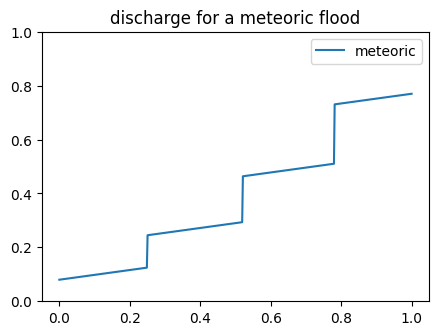

In [23]:
# your answer for 2 here
trib_locations = [0.25, 0.52, 0.78]  
trib_steps = [0.12, 0.17, 0.22]       

q_meteoric = 0.18*x + 0.08

for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric, label="meteoric")
ax.set_ylim(0, 1)
ax.set_title("discharge for a meteoric flood");
ax.legend();

<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
trib_locations = [0.25, 0.52, 0.78]   
trib_steps = [0.12, 0.17, 0.44]        

q_meteoric = 0.18*x + 0.08

for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric, label="meteoric")
ax.set_ylim(0, 1)
ax.set_title("discharge for a meteoric flood");
ax.legend()
```
---
![bigtrib](../figures/big_last_trib.png)

In [ ]:
# your answer for # 3 here
trib_locations = [0.25, 0.52, 0.78]   
trib_steps = [0.12, 0.17, 0.22, 0.05]

q_meteoric = 0.18*x + 0.08

for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric, label="meteoric")
ax.set_ylim(0, 1)
ax.set_title("discharge for a meteoric flood");
ax.legend();

<details>
<summary style="color:green;"><strong>Answer.</strong></summary>

```python
trib_locations = [0.25, 0.52, 0.78, 0.90]   
trib_steps = [0.12, 0.17, 0.22, 0.05, 0.05]

q_meteoric = 0.18*x + 0.08

for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, q_meteoric, label="meteoric")
ax.set_ylim(0, 1)
ax.set_title("discharge for a meteoric flood");
ax.legend()
```
---
![fourth trib](../figures/fourth_trib.png)

---
## Part 5 : make it look like a schematic

Our arrays are done! Now for the **style**. A schematic is about **shape**, so it should look different from a data figure:
|**a data figure has...**|**a schematic has...**| **because**|
|:--|:--|:--|
|numbers on the axis| **no numbers** (`ax.setxticks([])`)| the numbers were made up; showing them would pretend they're real|
|units on the axis labels| a label, but no units|there are no units|
|a box all the way around| just the left and bottom lines| it's simplier and draws the eye to the curve|
|a legend| **labels pointing at features**| "tributary" next to the step is easy to read than a key|

The four lines around the plot are called **spines**. You can hide any of them:
```python
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
```
Here's one panel, styled. Each new line is marked.

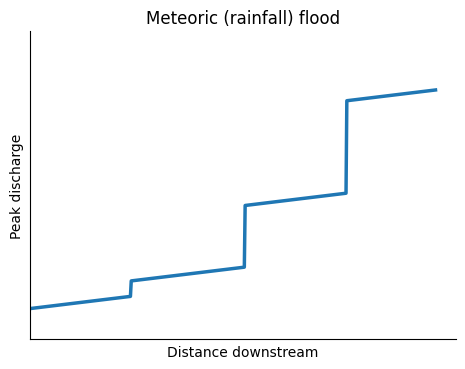

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4))

ax.plot(x, q_meteoric, color="tab:blue", linewidth=2.5)

ax.spines["top"].set_visible(False)       # NEW: hide two of the four box lines
ax.spines["right"].set_visible(False)
ax.set_xticks([])                         # NEW: no numbers on the axes
ax.set_yticks([])
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1)

ax.set_xlabel("Distance downstream")
ax.set_ylabel("Peak discharge")
ax.set_title("Meteoric (rainfall) flood");

### Arrowheads on the axes
Hand-drawn schematics often have arrows at the ends of the axes, meaning "more this way". This draws them:
```python
ax.plot(1, 0, ">", color="black", transform=ax.transAxes, clip_on=False)
ax.plot(0, 1, "^", color="black", transform=ax.transAxes, clip_on=False)
```
`transform=ax.transAxes` means "these coordinates are fractions of the axes box, not data values", so `(1, 0)` is always the bottom-right corner. `clip_on=False` lets the marker hang over the edge.

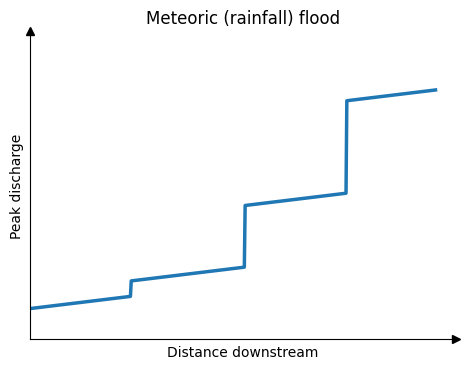

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4))

ax.plot(x, q_meteoric, color="tab:blue", linewidth=2.5)

ax.spines["top"].set_visible(False)       
ax.spines["right"].set_visible(False)
ax.plot(1, 0, ">", color="black", transform=ax.transAxes, clip_on=False)   # NEW
ax.plot(0, 1, "^", color="black", transform=ax.transAxes, clip_on=False)   # NEW
ax.set_xticks([])                         
ax.set_yticks([])
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1)

ax.set_xlabel("Distance downstream")
ax.set_ylabel("Peak discharge")
ax.set_title("Meteoric (rainfall) flood");

### Labels that point at features

`ax.annotate()` from Lecture 20 can point at each tributary. We need the **height of the curve** at each tributary to know where to point. The first point at or past the tributary is `q_meteoric[x >= location][0]`: a mask, then the first element.

Instead of placing each label by hand, we can say "put the text 8 points to the right and 12 points down from the spot," using `textcoords="offset points"`. Then the label moves with teh curve if you change the numbers.

Text(0.5, 1.0, 'Meteoric (rainfall) flood')

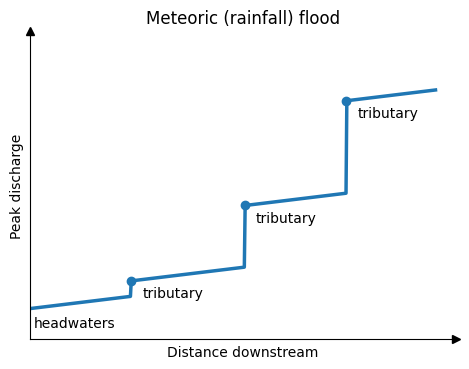

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4))

ax.plot(x, q_meteoric, color="tab:blue", linewidth=2.5)

for location in trib_locations:                                      # NEW: label each tributary
    height = q_meteoric[x >= location][0]
    ax.plot(location, height, "o", color="tab:blue")
    ax.annotate("tributary", xy=(location, height), xytext=(8, -12), textcoords="offset points")

ax.text(0.01, q_meteoric[0] - 0.06, "headwaters")                      # NEW

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.plot(1, 0, ">", color="black", transform=ax.transAxes, clip_on=False)
ax.plot(0, 1, "^", color="black", transform=ax.transAxes, clip_on=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1)

ax.set_xlabel("Distance downstream")
ax.set_ylabel("Peak discharge")
ax.set_title("Meteoric (rainfall) flood")


#### Let's move the tributaries around and see what happens


Text(0.5, 1.0, 'Meteoric (rainfall) flood')

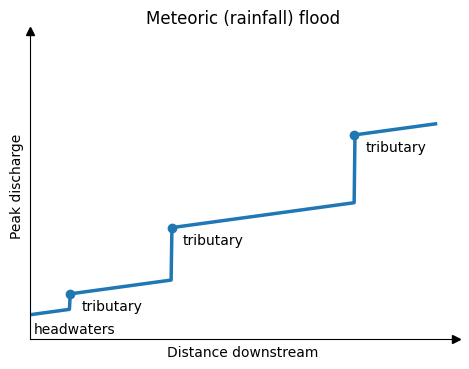

In [24]:
trib_locations = [0.1, 0.35, 0.8]   
trib_steps = [0.05, 0.17, 0.22]       

q_meteoric = 0.18*x + 0.08

for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, ax = plt.subplots(figsize=(5.5, 4))

ax.plot(x, q_meteoric, color="tab:blue", linewidth=2.5)

for location in trib_locations:                                      
    height = q_meteoric[x >= location][0]
    ax.plot(location, height, "o", color="tab:blue")
    ax.annotate("tributary", xy=(location, height), xytext=(8, -12), textcoords="offset points")

ax.text(0.01, q_meteoric[0] - 0.06, "headwaters")                      # NEW

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.plot(1, 0, ">", color="black", transform=ax.transAxes, clip_on=False)
ax.plot(0, 1, "^", color="black", transform=ax.transAxes, clip_on=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1)

ax.set_xlabel("Distance downstream")
ax.set_ylabel("Peak discharge")
ax.set_title("Meteoric (rainfall) flood")

#### Notice how the labels moved and we didn't have to do any work! 

### Lining text up with `ha` and `va`

When you write `ax.text(x, y, "words")`, matplotlib has to decide **which part** of the text sits on the point `(x, y)`. By default it's the **bottom-left** corner, so text always starts at the point and runs up and to the right. That's not always where you want it.

Two arguments let you choose:

| argument | stands for | options | what it controls |
|---|---|---|---|
| `ha=` | **h**orizontal **a**lignment | `"left"` (default), `"center"`, `"right"` | which **side** of the text touches the point |
| `va=` | **v**ertical **a**lignment | `"bottom"`, `"center"`, `"top"` | which **edge** of the text touches the point |

Read them as "**which part of the text** goes at my point": `ha="right"` means the text's **right** end sits at x, so the text extends to the **left**. `va="top"` means the text's **top** edge sits at y, so it hangs **below** the point. Run the cell below and look at where each label lands relative to its red dot.

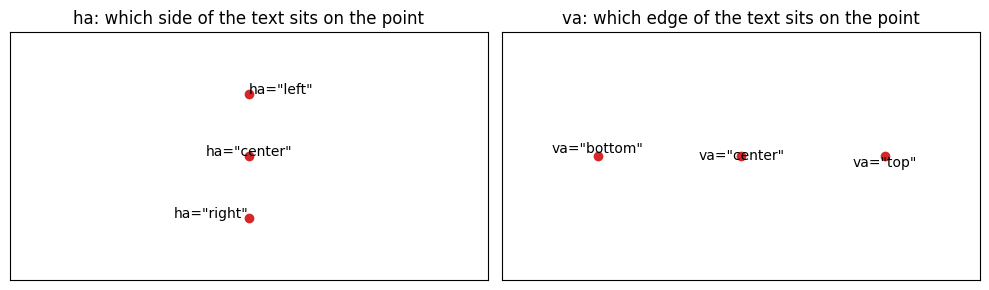

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for ha, y in zip(["left", "center", "right"], [0.75, 0.5, 0.25]):
    axes[0].plot(0.5, y, "o", color="tab:red")
    axes[0].text(0.5, y, f'ha="{ha}"', ha=ha)
axes[0].set_title("ha: which side of the text sits on the point")

for va, x in zip(["bottom", "center", "top"], [0.2, 0.5, 0.8]):
    axes[1].plot(x, 0.5, "o", color="tab:red")
    axes[1].text(x, 0.5, f'va="{va}"', va=va, ha="center")
axes[1].set_title("va: which edge of the text sits on the point")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

<div class="alert alert-info">

### Exercise 3 : finish the outburst panel, and put the two side by side

make a figure with **1 row and 2 columns**, 10 inches wide and 4.2 inches tall.

1. **Left:** the styled meteoric panel above.
2. **Right**: the outburst flood, styled the same way. Draw the background flow as a gray dashed line labeled "background flow" (with `ax.text()`), and the outburst as a thick line in a different color.
3. Mark the breach with a big dot at `x=0`, labeled "dam breach".
4. Use a `for ax in axes:` loop for everything both panels share: spines, ticks, limits, axis labels.
5. Add the axis arrowheads and save the figure at 300 dpi.
6. Push your figure to your Week 10 repository.

Feel free to change colors of these lines!

**Don't forget, to recreate any arrays that might have been changed in Exercise 2...**
    
</div>

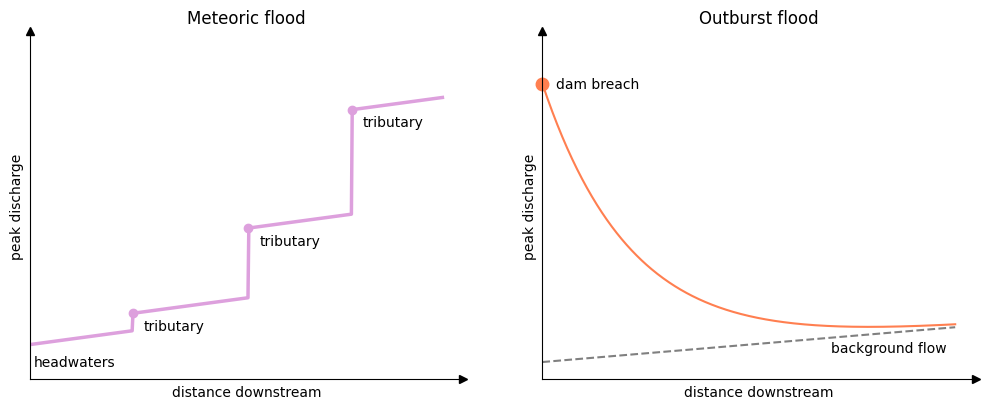

In [37]:
# your answer here
# setup
x = np.linspace(0, 1, 500)
trib_locations = [0.25, 0.53, 0.78]   # where each tributary joins (fraction of the way down)
trib_steps = [0.05, 0.2, 0.3]       # how much discharge each one adds

q_meteoric = 0.1 + 0.16*x
for location, amount in zip(trib_locations, trib_steps):
    q_meteoric[x >= location] += amount

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# everything the two panels share
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1)
    ax.set_xlabel("distance downstream")
    ax.set_ylabel("peak discharge")
    ax.plot(1, 0, ">", color="black", transform=ax.transAxes, clip_on=False)
    ax.plot(0, 1, "^", color="black", transform=ax.transAxes, clip_on=False)

# left: meteoric
axes[0].plot(x, q_meteoric, color="plum", linewidth=2.5)
for location in trib_locations:                                      
    height = q_meteoric[x >= location][0]
    axes[0].plot(location, height, "o", color="plum")
    axes[0].annotate("tributary", xy=(location, height), xytext=(8, -12), textcoords="offset points")
axes[0].text(0.01, q_meteoric[0] - 0.06, "headwaters")                                                 # NEW from class: This is what places our "headwaters" label on the meteoric flood plot
axes[0].set_title("Meteoric flood")

# right: outburst
axes[1].plot(x, q_background, linestyle="--", color="gray")#, label="background flow")                         # commented out the label because we don't want a legend, we want to write directly on the figure
axes[1].text(0.98, q_background[-1] - 0.04, "background flow", ha="right", va="top")                           # NEW from class: This will add our "background flow label:"
axes[1].plot(x, q_outburst, label="outburst", color="coral")
axes[1].plot(0, q_outburst[0], "o", color="coral", markersize=9, clip_on=False)                                # NEW from class: plots the marker at the dam breach
axes[1].annotate("dam breach", xy=(0, q_outburst[0]), xytext=(10, 0), textcoords="offset points", va="center") # NEW from class: this will add our "dam breach" label at the headwaters of the outburst plot
axes[1].set_title("Outburst flood")

# use tight layout
fig.tight_layout(w_pad=4)

# save


---
## Part 6 : your turn, from sketch to figure

In Lab 02, you saw that a fire cuts the soil's infiltration rate, so more rain becomes **runoff**. That changes the **hydrograph**: the plot of a stream's discharge over time during and after a storm.

Compared with an unburned watershed, after a fire:
- the peak discharge comes **sooner** (water runs off the surface instead of soaking in first),
- the peak is **higher** (more of thet rain becomes runoff), and
- the flow drops back down **faster** afterward (less water soacked in to drain out slowly later).

A hydrograph has a **rising limb** (discharge increasing up to the peak) and a **falling limb** (coming back down). A simple way to build one:
- before the peak: a straight line from the base flow up to the peak, `base + peak * t / t_peak`
- after the peak: exponential decay from the peak, `base + peak * np.exp(-(t - t_peak) / k)`

Use masks to fill in each part. You've done this exact move with `.loc[mask, "col"] = ...` in pandas; in NumPy it's `q[maks] = values[mask]`, where `values` is computed for every `t` at the mask picks which ones to keep.

<div class="alert alert-info">

### Exercise 4 : a burned vs. unburned hydrograph

1. **Sketch it first** on paper: time on x, discharge on y, one curve for an unburned watershed and one for a burned watershed. Make all three bullet points above true in your sketch.
2. Make a **pieces table** like the one in Part 2: which shape is the rising limb? Which is the falling limb? Look back at the function grid. What do you type for each?
3. Build it. Time runs from 0 to 24 hours after the storm starts (schematic, so the numbers are just for building it). Write a **function** that makes one hydrograph from a few "knobs" (base flow, peak size, time of the peak, how fast it drains), so you can call it twice: once with unburned numbers, once with burned numbers.
4. Plot both as a styled schematic: no tick numbers, two spines hidden, labels that point at the two peaks instead of a legend, and "schematic" in the title.
5. Save this figure and push it to your Week 10 repository.

</div>

<details>
<summary style="color:#1a5fa8;"><strong>Stuck? Hint 1: which shapes?</strong></summary>

The rising limb is a straight line from the base flow up to the peak (grid panel A). The falling limb drops fast at first and then levels off back toward the base flow (grid panel D).

</details>

<details>
<summary style="color:#1a5fa8;"><strong>Stuck? Hint 2: the formulas</strong></summary>

Rising: `base + peak * t / t_peak` (it equals `base` at `t = 0` and `base + peak` at the peak).
Falling: `base + peak * np.exp(-(t - t_peak) / k)` (it starts at `base + peak` right at the peak, then decays).

</details>

<details>
<summary style="color:#1a5fa8;"><strong>Stuck? Hint 3: joining the two pieces</strong></summary>

Compute the rising limb for **every** time, then use a mask to **replace** the times after the peak, the same move as `.loc[mask, "col"] = ...` in pandas:
```python
q = base + peak * t / t_peak
falling = t >= t_peak
q[falling] = (base + peak * np.exp(-(t - t_peak) / k))[falling]
```
The `[falling]` on the right keeps the two sides the same length.

</details>

<details>
<summary style="color:#1a5fa8;"><strong>Stuck? Hint 4: picking numbers</strong></summary>

Start with an unburned curve like `base=0.1, peak=1.0, t_peak=6, k=5`. For the burned curve, which knob makes the peak come **sooner**? **Higher**? Drop **faster**?

</details>

In [ ]:
# your answer here

---
## Summary: the recipe

1. **Sketch first.** What's on each axis? What shape is each curve? Where do the labels go?
2. **Break shapes into pieces.** Line: `start + slope * x`. Jump: `y[x >= location] += amount`. Decay: `np.exp(-x / length)`. Flat: `axhline`.
3. **Build one piece at a time**, plotting after each one, and keep the starting line in the same cell as the changes.
4. **Put the knobs in variables or lists** (tributary locations, decay length) so you can redraw it by changing a number.
5. **Style it as a schematic:** no tick numbers, no units, two spines hidden, labels pointing at features, and "schematic" in the title or caption.

| new today | what it does |
|---|---|
| `ax.spines["top"].set_visible(False)` | hides one of the four lines around the plot |
| `ax.set_xticks([])` | removes the tick marks and numbers |
| `textcoords="offset points"` | in `annotate`, places text a fixed distance from the point |
| `ha=`, `va=` | which corner of the text sits at the point you give |
| `y[mask] += amount` | adds to only the masked points |
| `q[mask] = values[mask]` | replaces only the masked points |
